# SIH PS 167 – BigEarthNet.txt + VRSBench data pipeline (Colab / Kaggle)

**What this notebook does**
1. Loads the **BigEarthNet.txt** text annotations (9.55M rows, ~0.5 GB) from Hugging Face.
2. Picks a **subset** of patches (default 2,000) and **streams** the Zenodo archives (`BigEarthNet-S1/S2.tar.zst`, 54 GB + 63 GB), keeping **only** the files for those patches. The full archives are never stored on disk.
3. Turns each patch into a Sentinel-2 RGB image and a Sentinel-1 SAR image (PNG).
4. Writes `train/validation/test` **JSONL** files (image paths + prompt/answer) ready for VLM fine-tuning.
5. Downloads **VRSBench** evaluation files (val images + eval JSONs).

Run the cells top to bottom. Turn **Internet ON** (Kaggle: Settings → Internet).

In [6]:
!pip -q install datasets zstandard rasterio

## 0. Config

In [7]:
import os, re, io, json, tarfile, shutil, time
import numpy as np, pandas as pd, pyarrow as pa, pyarrow.compute as pc
import requests, zstandard as zstd, rasterio
from PIL import Image
from tqdm.auto import tqdm

IS_KAGGLE = os.path.exists("/kaggle/working")
WORK = "/kaggle/working" if IS_KAGGLE else "/content"
ROOT = f"{WORK}/ben_subset"
os.makedirs(ROOT, exist_ok=True)

N_PATCHES = 2000   # how many image patches to build (each has ~20 text annotations)
N_TILES   = 3      # only sample from the first N tiles in the archive (fast). None = whole archive (slow, ~1h)
SEED      = 42

# Official BigEarthNet v2 (reBEN) archives on Zenodo
S2_URL = "https://zenodo.org/records/10891137/files/BigEarthNet-S2.tar.zst?download=1"
S1_URL = "https://zenodo.org/records/10891137/files/BigEarthNet-S1.tar.zst?download=1"

## 1. Load the BigEarthNet.txt annotations (text only)

In [8]:
from datasets import load_dataset
ds  = load_dataset("BIFOLD-BigEarthNetv2-0/BigEarthNet.txt")["all_data"]
tbl = ds.data.table if hasattr(ds.data, "table") else ds.data      # pyarrow Table, memory-mapped (no RAM blow-up)
print(tbl.num_rows, tbl.schema.names)

def top(col, k=12):
    vc = pc.value_counts(tbl[col]).to_pylist()
    return sorted(((d["values"], d["counts"]) for d in vc), key=lambda x: -x[1])[:k]

for col in ["type", "category", "split", "country", "season"]:
    print(f"\n{col}:", top(col))

9553962 ['ID', 's1_name', 'patch_id', 'input', 'output', 'type', 'category', 'split', 'latitude', 'longitude', 'country', 'season', 'climate_zone']

type: [('binary', 3625160), ('mcq', 3259184), ('bounding box', 2205686), ('captioning', 463932)]

category: [('presence', 1391053), ('area', 1390845), ('count', 1390730), ('adjacency', 1222128), ('point', 1143883), ('reference', 1061803), ('None', 463932), ('season', 463662), ('climate zone', 463637), ('country', 463274), ('relative pos', 99015)]

split: [('train', 4674281), ('validation', 2454690), ('test', 2409962), ('bench', 15029)]

country: [('Finland', 3015585), ('Portugal', 1823941), ('Serbia', 1484576), ('Lithuania', 1069085), ('Austria', 904001), ('Ireland', 810044), ('Belgium', 234456), ('Switzerland', 101939), ('Luxembourg', 76977), ('Kosovo', 33358)]

season: [('Spring', 3304787), ('Fall', 2837657), ('Summer', 1937503), ('Winter', 1474015)]


### 1b. Look at real examples
Check what `input` / `output` look like for each annotation `type` (caption, VQA, referring, ...). This decides how you format prompts when fine-tuning.

In [9]:
sample = tbl.slice(0, 3000).to_pandas()
for t, g in sample.groupby("type"):
    r = g.iloc[0]
    print(f"--- type={t} | category={r['category']} | split={r['split']}")
    print("INPUT :", str(r["input"])[:400])
    print("OUTPUT:", str(r["output"])[:400], "\n")

--- type=binary | category=adjacency | split=test
INPUT : Would you say that any arable land lies next to pastures in the image?
OUTPUT: yes 

--- type=bounding box | category=point | split=test
INPUT : Provide a bounding box for the land cover class instance at <point>(0.82, 0.28)</point> in the satellite image.
OUTPUT: [0.64 0.0, 1.0 0.71] 

--- type=captioning | category=None | split=test
INPUT : Give a detailed overview of this satellite scene, including the region and land cover classes.
OUTPUT: This satellite image, captured in Austria during summer, depicts a diverse landscape dominated by agricultural and forested areas within the "cold, no dry season, warm summer" climate zone. Arable land (~708,000 sqm) is the most prominent feature, covering a large area and bordering broad-leaved forest (~413,000 sqm) and pastures (~115,000 sqm), which are distributed across two areas, one of which 

--- type=mcq | category=adjacency | split=test
INPUT : Which classes share a boundary? a) B

## 2. Choose the patch subset

In [10]:
# one row per patch (≈464k), not per annotation (9.5M)
patches = (tbl.select(["patch_id", "s1_name", "split"])
              .group_by(["patch_id", "s1_name", "split"]).aggregate([]).to_pandas())
assert patches.patch_id.str.startswith("S2").all(), "patch_id is not a Sentinel-2 patch name - check columns"
assert patches.s1_name.str.startswith("S1").all(),  "s1_name is not a Sentinel-1 name - check columns"

# tile = Sentinel-2 product + MGRS tile, e.g. S2B_MSIL2A_20170808T094029_N9999_R036_T34VFM
patches["tile"] = patches.patch_id.str.rsplit("_", n=2).str[0]
print(len(patches), "patches in", patches.tile.nunique(), "tiles")
print(patches.split.value_counts())

464044 patches in 115 tiles
split
train         229114
validation    118095
test          115753
bench           1082
Name: count, dtype: int64


The archives are huge `.tar.zst` files read as a **stream**. Streaming is much faster if your patches sit at the **start** of the archive, so we peek at which tiles come first.

In [11]:
class _Counting:
    """File-like wrapper that shows download progress."""
    def __init__(self, raw, desc):
        self.raw, self.bar = raw, tqdm(unit="B", unit_scale=True, desc=desc)
    def read(self, n=-1):
        b = self.raw.read(n); self.bar.update(len(b)); return b
    def close(self): self.bar.close(); self.raw.close()

def open_tar_stream(src, desc="stream"):
    """Open a .tar.zst (URL or local path) as a streaming tar. Nothing is written to disk."""
    if str(src).startswith("http"):
        for attempt in range(4):
            try:
                r = requests.get(src, stream=True, timeout=60); r.raise_for_status(); break
            except Exception as e:
                print("retry", attempt, e); time.sleep(5)
        raw = r.raw
    else:
        raw = open(src, "rb")
    src_f = _Counting(raw, desc)
    tf = tarfile.open(fileobj=zstd.ZstdDecompressor().stream_reader(src_f), mode="r|")
    tf._src = src_f
    return tf

S2_PAT = re.compile(r"^S2[AB]_MSIL2A_.+_T\d{2}[A-Z]{3}_\d+_\d+$")

def first_tiles(src, n_tiles):
    """Return the first n_tiles tile names encountered in the archive."""
    tiles, tf = [], open_tar_stream(src, "peek tiles")
    try:
        for m in tf:
            for p in m.name.split("/"):
                if S2_PAT.match(p):
                    t = p.rsplit("_", 2)[0]
                    if t not in tiles: tiles.append(t)
            if len(tiles) > n_tiles: break          # tile n+1 started -> first n are complete
    finally:
        tf._src.close()
    return tiles[:n_tiles]

if N_TILES:
    tiles = first_tiles(S2_URL, N_TILES)
    print("using tiles:", tiles)
    pool = patches[patches.tile.isin(tiles)]
else:
    pool = patches
sub = pool.sample(min(N_PATCHES, len(pool)), random_state=SEED).reset_index(drop=True)
print(len(pool), "patches available ->", len(sub), "selected")
print(sub.split.value_counts())

peek tiles: 0.00B [00:00, ?B/s]

using tiles: ['S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP', 'S2A_MSIL2A_20170613T101031_N9999_R022_T34VER', 'S2A_MSIL2A_20170617T113321_N9999_R080_T29UPU']
17093 patches available -> 2000 selected
split
train         942
test          540
validation    510
bench           8
Name: count, dtype: int64


## 3. Stream the archives and keep only the selected patches

In [12]:
def extract_wanted(src, wanted_ids, out_dir, desc):
    """Stream the archive once; save only .tif files that belong to a wanted patch folder. Stops early when done."""
    os.makedirs(out_dir, exist_ok=True)
    wanted, seen = set(wanted_ids), set()
    tf = open_tar_stream(src, desc)
    try:
        for m in tf:
            pid = next((p for p in m.name.split("/") if p in wanted), None)
            if pid is None:
                if len(seen) == len(wanted): break            # passed the last wanted patch
                continue
            if not (m.isfile() and m.name.endswith(".tif")): continue
            d = os.path.join(out_dir, pid); os.makedirs(d, exist_ok=True)
            with open(os.path.join(d, m.name.split("/")[-1]), "wb") as f:
                f.write(tf.extractfile(m).read())
            seen.add(pid)
    finally:
        tf._src.close()
    return seen

S2_DIR, S1_DIR = f"{ROOT}/raw_s2", f"{ROOT}/raw_s1"

t0 = time.time(); seen2 = extract_wanted(S2_URL, sub.patch_id, S2_DIR, "S2 stream")
print(f"S2: {len(seen2)}/{len(sub)} patches in {(time.time()-t0)/60:.1f} min")

S2 stream: 0.00B [00:00, ?B/s]

S2: 2000/2000 patches in 5.9 min


In [13]:
t0 = time.time(); seen1 = extract_wanted(S1_URL, sub.s1_name, S1_DIR, "S1 stream")
print(f"S1: {len(seen1)}/{len(sub)} patches in {(time.time()-t0)/60:.1f} min")

sub = sub[sub.patch_id.isin(seen2) & sub.s1_name.isin(seen1)].reset_index(drop=True)
print("patches with BOTH S1 and S2:", len(sub))

S1 stream: 0.00B [00:00, ?B/s]

S1: 2000/2000 patches in 84.6 min
patches with BOTH S1 and S2: 2000


## 4. Convert patches to images
* **S2 RGB**: bands B04/B03/B02, percentile-stretched.
* **S1 SAR**: false colour `R=VV, G=VH, B=VV−VH` (the data is in dB).

Add more S2 bands here later if your model takes multispectral input.

In [14]:
def read_band(path, size=120):
    with rasterio.open(path) as d:
        a = d.read(1).astype("float32")
    if a.shape != (size, size):
        a = np.array(Image.fromarray(a).resize((size, size), Image.BILINEAR))
    return a

def stretch(a, lo=2, hi=98):
    l, h = np.percentile(a, [lo, hi]); return np.clip((a - l) / (h - l + 1e-6), 0, 1)

def s2_rgb(pid):
    d = f"{S2_DIR}/{pid}"
    return (np.stack([stretch(read_band(f"{d}/{pid}_{b}.tif")) for b in ("B04", "B03", "B02")], -1) * 255).astype("uint8")

def s1_rgb(sid):
    d = f"{S1_DIR}/{sid}"
    vv, vh = read_band(f"{d}/{sid}_VV.tif"), read_band(f"{d}/{sid}_VH.tif")
    return (np.stack([stretch(vv), stretch(vh), stretch(vv - vh)], -1) * 255).astype("uint8")

IMG_DIR = f"{ROOT}/images"; os.makedirs(f"{IMG_DIR}/s2", exist_ok=True); os.makedirs(f"{IMG_DIR}/s1", exist_ok=True)
ok = []
for r in tqdm(sub.itertuples(), total=len(sub)):
    try:
        Image.fromarray(s2_rgb(r.patch_id)).save(f"{IMG_DIR}/s2/{r.patch_id}.png")
        Image.fromarray(s1_rgb(r.s1_name)).save(f"{IMG_DIR}/s1/{r.s1_name}.png")
        ok.append(True)
    except Exception as e:
        ok.append(False); print("skip", r.patch_id, e)
sub = sub[ok].reset_index(drop=True)
print("images ready:", len(sub))

  0%|          | 0/2000 [00:00<?, ?it/s]

images ready: 2000


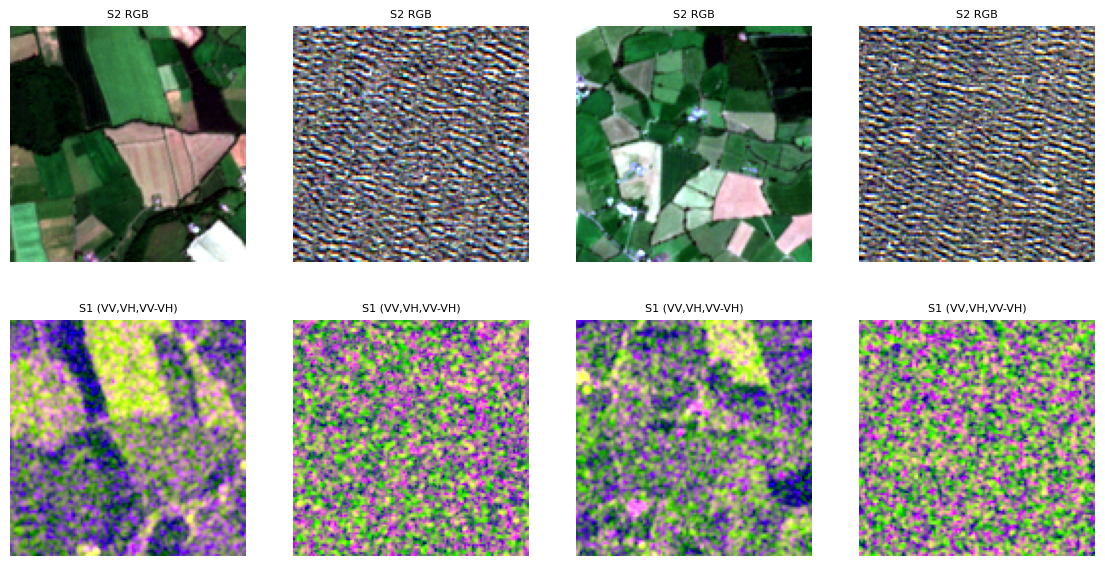

In [15]:
# quick visual check
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    r = sub.iloc[i]
    ax[0, i].imshow(Image.open(f"{IMG_DIR}/s2/{r.patch_id}.png")); ax[0, i].set_title("S2 RGB", fontsize=8)
    ax[1, i].imshow(Image.open(f"{IMG_DIR}/s1/{r.s1_name}.png")); ax[1, i].set_title("S1 (VV,VH,VV-VH)", fontsize=8)
    ax[0, i].axis("off"); ax[1, i].axis("off")
plt.show()

## 5. Build fine-tuning JSONL (image paths + prompt/answer)

In [16]:
mask = pc.is_in(tbl["patch_id"], value_set=pa.array(sub.patch_id.tolist()))
ann  = tbl.filter(mask).to_pandas()
ann  = ann.merge(sub[["patch_id"]].assign(has_img=True), on="patch_id")
print(len(ann), "annotations for", ann.patch_id.nunique(), "patches")
print(ann.type.value_counts())

OUT = f"{ROOT}/jsonl"; os.makedirs(OUT, exist_ok=True)
counts = {}
for split, g in ann.groupby("split"):
    path = f"{OUT}/{split}.jsonl"
    with open(path, "w") as f:
        for r in g.itertuples():
            f.write(json.dumps({
                "id": r.ID, "patch_id": r.patch_id, "type": r.type, "category": r.category, "split": r.split,
                "images": {"s2_rgb": f"{IMG_DIR}/s2/{r.patch_id}.png", "s1": f"{IMG_DIR}/s1/{r.s1_name}.png"},
                "messages": [{"role": "user", "content": r.input}, {"role": "assistant", "content": r.output}],
            }) + "\n")
    counts[split] = len(g)
print("written:", counts, "->", OUT)

38396 annotations for 2000 patches
type
binary          15398
mcq             13666
bounding box     7333
captioning       1999
Name: count, dtype: int64
written: {'bench': 131, 'test': 10330, 'train': 17850, 'validation': 10085} -> /kaggle/working/ben_subset/jsonl


### 5b. A loader you can plug into training
Plain map-style dataset (works with a PyTorch `DataLoader` or Hugging Face `Trainer`). Inspect one example first: if `input` already contains an image placeholder, don't add another one when you build chat messages.

In [17]:
class BigEarthNetTxt:
    def __init__(self, jsonl_path, use_sar=True):
        self.rows = [json.loads(l) for l in open(jsonl_path)]
        self.use_sar = use_sar
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        r = self.rows[i]
        imgs = [Image.open(r["images"]["s2_rgb"]).convert("RGB")]
        if self.use_sar: imgs.append(Image.open(r["images"]["s1"]).convert("RGB"))
        return {"images": imgs, "prompt": r["messages"][0]["content"], "answer": r["messages"][1]["content"], "type": r["type"]}

split_name = sorted(counts)[0]
d = BigEarthNetTxt(f"{OUT}/{split_name}.jsonl")
ex = d[0]
print(split_name, len(d), "| images:", [im.size for im in ex["images"]])
print("PROMPT:", ex["prompt"][:300]); print("ANSWER:", ex["answer"][:300])

bench 131 | images: [(120, 120), (120, 120)]
PROMPT: Does any mixed forest and pastures share a common boundary?
ANSWER: yes


## 6. VRSBench (evaluation benchmark)
Only the **val** images and the eval JSONs are needed for evaluation (~4 GB). Hugging Face repo: `xiang709/VRSBench`.

In [18]:
from huggingface_hub import hf_hub_download
VRS = f"{WORK}/vrsbench"; os.makedirs(VRS, exist_ok=True)
for f in ["VRSBench_EVAL_Cap.json", "VRSBench_EVAL_vqa.json", "VRSBench_EVAL_referring.json", "Images_val.zip"]:
    hf_hub_download("xiang709/VRSBench", f, repo_type="dataset", local_dir=VRS)
shutil.unpack_archive(f"{VRS}/Images_val.zip", f"{VRS}/Images_val")
print(os.listdir(VRS))

VRSBench_EVAL_Cap.json:   0%|          | 0.00/4.81M [00:00<?, ?B/s]

VRSBench_EVAL_vqa.json:   0%|          | 0.00/9.36M [00:00<?, ?B/s]

VRSBench_EVAL_referring.json:   0%|          | 0.00/10.3M [00:00<?, ?B/s]

Images_val.zip: reconstructing file:   0%|          |  0.00B / 3.98GB            

Images_val.zip: downloading bytes:           |  0.00B            

['VRSBench_EVAL_Cap.json', 'Images_val', 'VRSBench_EVAL_vqa.json', '.cache', 'VRSBench_EVAL_referring.json', 'Images_val.zip']


In [19]:
for name in ["Cap", "vqa", "referring"]:
    data = json.load(open(f"{VRS}/VRSBench_EVAL_{name}.json"))
    print(name, type(data).__name__, len(data)); print(json.dumps(data[0] if isinstance(data, list) else data, indent=1)[:600], "\n")

Cap list 9350
{
 "image_id": "P0003_0002.png",
 "ground_truth": "The aerial image from GoogleEarth features a group of large yellow buses lined up on the left side, and two small vehicles, one on the top-right and another large vehicle on the bottom-right side of the image. The buses are parked in a lot adjacent to a green area and a road running roughly north-south.",
 "question": "Describe the image in detail",
 "dataset": "RSBench",
 "question_id": 0,
 "type": "caption"
} 

vqa list 37409
{
 "image_id": "P0003_0002.png",
 "question": "What color are the large vehicles seen in the image?",
 "ground_truth": "Yellow",
 "dataset": "RSBench",
 "question_id": 0,
 "type": "object color"
} 

referring list 16159
{
 "image_id": "P0003_0002.png",
 "question": "The large yellow vehicle situated closest to the green area.",
 "ground_truth": "{<25><40><33><60>}",
 "dataset": "RSBench",
 "question_id": 0,
 "type": "ref",
 "unique": false,
 "obj_corner": [
  0.333984375,
  0.58984375,
  0.28710937

## 7. Save so you don't redo the 30-60 min stream
Zip the subset (images + JSONL) and copy to Google Drive (Colab) or keep it as a Kaggle output / new dataset.

In [20]:
archive = shutil.make_archive(f"{WORK}/bigearthnet_txt_subset", "zip", ROOT, "images")
shutil.copy(f"{OUT}/train.jsonl", WORK) if os.path.exists(f"{OUT}/train.jsonl") else None
print("saved:", archive, f"({os.path.getsize(archive)/1e6:.0f} MB)")
# Colab only:
# from google.colab import drive; drive.mount("/content/drive"); shutil.copy(archive, "/content/drive/MyDrive/")

saved: /kaggle/working/bigearthnet_txt_subset.zip (145 MB)


In [21]:
!pip -q install einops huggingface_hub
!git clone -q https://github.com/antofuller/CROMA.git {WORK}/CROMA

In [22]:
import glob, sys
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

sys.path.append(f"{WORK}/CROMA")          # use_croma.py is in the repo root
from use_croma import PretrainedCROMA

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WEIGHTS = hf_hub_download("antofuller/CROMA", "CROMA_base.pt")   # use CROMA_large.pt for the large model

# CROMA wants 12 optical bands (no B10 cirrus) in this order, and 2 SAR channels (VV, VH)
S2_BANDS = ["B01","B02","B03","B04","B05","B06","B07","B08","B8A","B09","B11","B12"]

def normalize(x, use_8_bit=True, mean=None, std=None):
    """README normalisation (mean +/- 2 std per channel -> 0..1). x: (N,C,H,W).
    If mean/std (shape C) are given they are used instead of batch statistics (recommended for training)."""
    x = x.float(); out = []
    for c in range(x.shape[1]):
        m = x[:, c].mean() if mean is None else mean[c]
        s = x[:, c].std()  if std  is None else std[c]
        lo, hi = m - 2 * s, m + 2 * s
        img = ((x[:, c] - lo) / (hi - lo + 1e-6)).clamp(0, 1)
        if use_8_bit: img = (img * 255).to(torch.uint8).float() / 255   # same quantisation as the README
        out.append(img.unsqueeze(1))
    return torch.cat(out, 1)

CROMA_base.pt: reconstructing file:   0%|          |  0.00B /  778MB            

CROMA_base.pt: downloading bytes:           |  0.00B            

In [23]:
def load_ben_pair(pid, sid, s2_dir, s1_dir):
    s2 = np.stack([read_band(f"{s2_dir}/{pid}/{pid}_{b}.tif") for b in S2_BANDS])          # (12,120,120)
    s1 = np.stack([read_band(f"{s1_dir}/{sid}/{sid}_{p}.tif") for p in ("VV", "VH")])      # (2,120,120)
    return s2, s1

def run_sample(s2, s1, size="base", res=120):
    model = PretrainedCROMA(pretrained_path=WEIGHTS, size=size, modality="both", image_resolution=res).to(DEVICE).eval()
    o = torch.from_numpy(s2)[None]; r = torch.from_numpy(s1)[None]
    o, r = normalize(o).to(DEVICE), normalize(r).to(DEVICE)
    with torch.no_grad():
        out = model(SAR_images=r, optical_images=o)
    for k, v in out.items(): print(k, tuple(v.shape))
    return out

# real pair from the subset built above (`sub`, `S2_DIR`, `S1_DIR` come from sections 2-3)
pid, sid = sub.patch_id[0], sub.s1_name[0]
s2_sample, s1_sample = load_ben_pair(pid, sid, S2_DIR, S1_DIR)
print(pid, sid, s2_sample.shape, s1_sample.shape)
out = run_sample(s2_sample, s1_sample)

S2A_MSIL2A_20170617T113321_N9999_R080_T29UPU_23_56 S1A_IW_GRDH_1SDV_20170617T064724_29UPU_23_56 (12, 120, 120) (2, 120, 120)
Initializing SAR encoder
Initializing optical encoder
Initializing joint SAR-optical encoder
SAR_encodings (1, 225, 768)
SAR_GAP (1, 768)
optical_encodings (1, 225, 768)
optical_GAP (1, 768)
joint_encodings (1, 225, 768)
joint_GAP (1, 768)


In [24]:
import requests, concurrent.futures as cf
FLOOD_ROOT = f"{WORK}/sen1floods11"; SPL = f"{FLOOD_ROOT}/splits"
for d in ("S1Hand", "S2Hand", "LabelHand"): os.makedirs(f"{FLOOD_ROOT}/{d}", exist_ok=True)
os.makedirs(SPL, exist_ok=True)
BUCKET = "https://storage.googleapis.com/sen1floods11"       # public bucket, plain HTTPS (no gsutil / login needed)
HAND = f"{BUCKET}/v1.1/data/flood_events/HandLabeled"

def fetch(url, dst, tries=3):
    if os.path.exists(dst) and os.path.getsize(dst) > 0: return True
    for _ in range(tries):
        try:
            r = requests.get(url, timeout=120)
            if r.status_code == 200:
                open(dst, "wb").write(r.content); return True
        except requests.RequestException: pass
    return False

# 1) split csv files (list the bucket so we get the exact names)
objs = requests.get("https://storage.googleapis.com/storage/v1/b/sen1floods11/o",
                    params={"prefix": "v1.1/splits/flood_handlabeled/", "maxResults": 1000}, timeout=60).json().get("items", [])
for o in objs:
    if o["name"].endswith(".csv"): fetch(f"{BUCKET}/{o['name']}", f"{SPL}/{os.path.basename(o['name'])}")
print("split files:", sorted(os.listdir(SPL)))
assert os.listdir(SPL), "No split files downloaded: turn Internet ON in the notebook settings and re-run"

# 2) chip names from the split csvs (they may list the S1Hand or S2Hand file name, so strip either suffix)
def chip_names(csv):
    return pd.read_csv(csv, header=None)[0].str.replace(r"_S[12]Hand\.tif$", "", regex=True).tolist()

NEEDED = ["flood_train_data.csv", "flood_valid_data.csv", "flood_test_data.csv"]
chips = sorted({n for f in NEEDED if os.path.exists(f"{SPL}/{f}") for n in chip_names(f"{SPL}/{f}")})
jobs = [(f"{HAND}/{k}/{n}_{k}.tif", f"{FLOOD_ROOT}/{k}/{n}_{k}.tif") for n in chips for k in ("S1Hand", "S2Hand", "LabelHand")]
with cf.ThreadPoolExecutor(16) as ex: ok = list(tqdm(ex.map(lambda j: fetch(*j), jobs), total=len(jobs)))
print(f"downloaded {sum(ok)}/{len(jobs)} files for {len(chips)} chips")


split files: ['flood_bolivia_data.csv', 'flood_test_data.csv', 'flood_train_data.csv', 'flood_valid_data.csv']


  0%|          | 0/1293 [00:00<?, ?it/s]

downloaded 1293/1293 files for 431 chips


In [25]:
S2_IDX = [0,1,2,3,4,5,6,7,8,9,11,12]      # 13 bands (B1..B12 incl. B10) -> drop B10 (index 10)
TILE = 128

def read_tif(p):
    with rasterio.open(p) as d: return d.read().astype("float32")

class Sen1Floods11(Dataset):
    def __init__(self, split_csv, train, mean=None, std=None):
        self.names = chip_names(split_csv)                     # chip ids, e.g. Bolivia_103757
        self.train, self.mean, self.std = train, mean, std
        self.tiles = [(i, t) for i in range(len(self.names)) for t in range(16)]   # used for eval
    def __len__(self): return len(self.names) if self.train else len(self.tiles)
    def load(self, n):
        s2 = np.nan_to_num(read_tif(f"{FLOOD_ROOT}/S2Hand/{n}_S2Hand.tif")[S2_IDX])
        s1 = np.nan_to_num(read_tif(f"{FLOOD_ROOT}/S1Hand/{n}_S1Hand.tif"))
        y  = read_tif(f"{FLOOD_ROOT}/LabelHand/{n}_LabelHand.tif")[0].astype("int64")
        return s2, s1, y
    def __getitem__(self, k):
        if self.train: i = k; r, c = np.random.randint(0, 512 - TILE + 1, 2)
        else:          i, t = self.tiles[k]; r, c = (t // 4) * TILE, (t % 4) * TILE
        s2, s1, y = self.load(self.names[i])
        sl = (slice(None), slice(r, r + TILE), slice(c, c + TILE))
        s2, s1, y = s2[sl], s1[sl], y[r:r + TILE, c:c + TILE]
        if self.train and np.random.rand() < .5: s2, s1, y = s2[..., ::-1], s1[..., ::-1], y[:, ::-1]
        if self.train and np.random.rand() < .5: s2, s1, y = s2[:, ::-1], s1[:, ::-1], y[::-1]
        s2 = torch.from_numpy(np.ascontiguousarray(s2)); s1 = torch.from_numpy(np.ascontiguousarray(s1))
        # fixed dataset-level stats (same for every sample) -> consistent inputs
        s2 = normalize(s2[None], mean=self.mean["s2"], std=self.std["s2"])[0]
        s1 = normalize(s1[None], mean=self.mean["s1"], std=self.std["s1"])[0]
        return s2, s1, torch.from_numpy(np.ascontiguousarray(y))

def dataset_stats(csv, n=60):
    names = pd.Series(chip_names(csv)).sample(n, random_state=0)
    a2, a1 = [], []
    for nm in names:
        a2.append(np.nan_to_num(read_tif(f"{FLOOD_ROOT}/S2Hand/{nm}_S2Hand.tif")[S2_IDX]).reshape(12, -1))
        a1.append(np.nan_to_num(read_tif(f"{FLOOD_ROOT}/S1Hand/{nm}_S1Hand.tif")).reshape(2, -1))
    a2, a1 = np.concatenate(a2, 1), np.concatenate(a1, 1)
    return {"s2": a2.mean(1), "s1": a1.mean(1)}, {"s2": a2.std(1), "s1": a1.std(1)}

print(glob.glob(f"{SPL}/*"))                                   # check the exact csv names
TR, VA = f"{SPL}/flood_train_data.csv", f"{SPL}/flood_valid_data.csv"
MEAN, STD = dataset_stats(TR)
train_ds = Sen1Floods11(TR, True, MEAN, STD); val_ds = Sen1Floods11(VA, False, MEAN, STD)
train_dl = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2, drop_last=True)
val_dl   = DataLoader(val_ds,   batch_size=32, num_workers=2)
print(len(train_ds), "train chips |", len(val_ds), "val tiles")

['/kaggle/working/sen1floods11/splits/flood_train_data.csv', '/kaggle/working/sen1floods11/splits/flood_valid_data.csv', '/kaggle/working/sen1floods11/splits/flood_test_data.csv', '/kaggle/working/sen1floods11/splits/flood_bolivia_data.csv']
252 train chips | 1424 val tiles


In [26]:
class CROMASeg(nn.Module):
    def __init__(self, res=TILE, size="base", freeze=True, n_cls=2):
        super().__init__()
        self.enc = PretrainedCROMA(pretrained_path=WEIGHTS, size=size, modality="both", image_resolution=res)
        self.freeze, self.g = freeze, res // 8
        if freeze:
            for p in self.enc.parameters(): p.requires_grad = False
        with torch.no_grad():
            d = self.enc(SAR_images=torch.zeros(1, 2, res, res), optical_images=torch.zeros(1, 12, res, res))["joint_encodings"].shape[-1]
        blk = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.GELU())
        self.head = nn.Sequential(blk(d, 256), nn.Upsample(scale_factor=2, mode="bilinear"), blk(256, 128),
                                  nn.Upsample(scale_factor=2, mode="bilinear"), blk(128, 64),
                                  nn.Upsample(scale_factor=2, mode="bilinear"), nn.Conv2d(64, n_cls, 1))
    def forward(self, s2, s1):
        if self.freeze:
            self.enc.eval()
            with torch.no_grad(): z = self.enc(SAR_images=s1, optical_images=s2)["joint_encodings"]
        else:
            z = self.enc(SAR_images=s1, optical_images=s2)["joint_encodings"]
        B, N, D = z.shape
        return self.head(z.transpose(1, 2).reshape(B, D, self.g, self.g))     # (B, n_cls, res, res)

FREEZE, EPOCHS = True, 10
model = CROMASeg(freeze=FREEZE).to(DEVICE)
params = [{"params": model.head.parameters(), "lr": 1e-3}]
if not FREEZE: params.append({"params": model.enc.parameters(), "lr": 1e-5})
opt = torch.optim.AdamW(params, weight_decay=1e-2)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS * len(train_dl))
scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")

@torch.no_grad()
def evaluate(dl):
    model.eval(); inter = union = 0
    for s2, s1, y in dl:
        p = model(s2.to(DEVICE), s1.to(DEVICE)).argmax(1).cpu(); v = y >= 0          # ignore -1 pixels
        inter += ((p == 1) & (y == 1) & v).sum().item(); union += (((p == 1) | (y == 1)) & v).sum().item()
    return inter / max(union, 1)                                                      # IoU of the water class

best = 0
for ep in range(EPOCHS):
    model.train(); tot = 0
    for s2, s1, y in tqdm(train_dl, desc=f"epoch {ep}"):
        s2, s1, y = s2.to(DEVICE), s1.to(DEVICE), y.to(DEVICE)
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            loss = F.cross_entropy(model(s2, s1), y, ignore_index=-1)
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step(); tot += loss.item()
    iou = evaluate(val_dl); print(f"epoch {ep} loss {tot/len(train_dl):.4f} val water-IoU {iou:.4f}")
    if iou > best: best = iou; torch.save(model.state_dict(), "croma_sen1floods11.pt")

Initializing SAR encoder
Initializing optical encoder
Initializing joint SAR-optical encoder


/tmp/ipykernel_50/2092835807.py:29: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")


epoch 0:   0%|          | 0/15 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e9c3fa0b6a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e9c3fa0b6a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch 0 loss 0.4483 val water-IoU 0.6357


epoch 1:   0%|          | 0/15 [00:00<?, ?it/s]

... (22 outputs left out)

epoch 8 loss 0.1317 val water-IoU 0.6861


epoch 9:   0%|          | 0/15 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e9c3fa0b6a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e9c3fa0b6a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch 9 loss 0.1261 val water-IoU 0.7005


In [27]:
CLOUD_THRESHOLD = 10.0     # percent

def cloud_percent_scl(scl):
    """scl: 2-D array of SCL codes. Cloud = 8 (medium prob), 9 (high prob), 10 (thin cirrus). 0 = no data is excluded."""
    valid = scl != 0
    return 100.0 * np.isin(scl, [8, 9, 10])[valid].sum() / max(valid.sum(), 1)

def cloud_percent_heuristic(s2, bands, scale=10000.0):
    """s2: (C,H,W) reflectance x10000 (DN). bands: list of band names matching axis 0 (needs B02,B03,B04,B08,B11)."""
    b = {n: s2[i] / scale for i, n in enumerate(bands)}
    valid = s2.sum(0) > 0                                              # nodata = all zeros
    vis = (b["B02"] + b["B03"] + b["B04"]) / 3
    stack = np.stack([b["B02"], b["B03"], b["B04"], b["B08"]])
    whiteness = np.abs(stack - stack.mean(0)).mean(0) / (stack.mean(0) + 1e-6)
    ndsi = (b["B03"] - b["B11"]) / (b["B03"] + b["B11"] + 1e-6)        # high for snow, low for cloud
    cloud = (vis > 0.20) & (whiteness < 0.20) & (ndsi < 0.40)
    if "B10" in b: cloud |= b["B10"] > 0.012                           # cirrus band (L1C only)
    return 100.0 * (cloud & valid).sum() / max(valid.sum(), 1)

def check_scene(s2=None, bands=None, scl=None):
    pct = cloud_percent_scl(scl) if scl is not None else cloud_percent_heuristic(s2, bands)
    flag = pct > CLOUD_THRESHOLD
    print(f"cloud cover: {pct:.1f}%  ->  {'FLAG (>10%)' if flag else 'OK'}")
    return pct, flag

# sanity test on synthetic data: left 30% of the scene is bright-white "cloud", rest is dark vegetation-like
t = np.full((12, 100, 100), 800.0); t[:, :, :30] = 4000.0
check_scene(s2=t, bands=S2_BANDS)           # expect ~30% -> FLAG

# real BigEarthNet patch from your subset:
_ = check_scene(s2=s2_sample, bands=S2_BANDS)
# a Sen1Floods11 chip:
# s2_13 = read_tif(f"{FLOOD_ROOT}/S2Hand/Bolivia_103757_S2Hand.tif")
# check_scene(s2=s2_13, bands=["B01","B02","B03","B04","B05","B06","B07","B08","B8A","B09","B10","B11","B12"])

cloud cover: 30.0%  ->  FLAG (>10%)
cloud cover: 0.0%  ->  OK
